In [1]:
from google.colab import drive
import os
os.chdir('/content')
drive.mount('/content/drive', force_remount=True)
os.chdir('/content/drive/MyDrive/3dgs_decomposition')

Mounted at /content/drive


In [2]:
!pip install lpips

In [3]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import numpy as np
import csv
import pandas as pd

In [4]:
!pip install -r intr_decomp_3dgs/requirements.txt
!pip install intr_decomp_3dgs/diff-gaussian-rasterization  --no-build-isolation -v

Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
Processing ./intr_decomp_3dgs/diff-gaussian-rasterization
  Running command Preparing metadata (pyproject.toml)
  running dist_info
  creating /tmp/pip-modern-metadata-00h_sxyz/diff_gaussian_rasterization.egg-info
  writing /tmp/pip-modern-metadata-00h_sxyz/diff_gaussian_rasterization.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-modern-metadata-00h_sxyz/diff_gaussian_rasterization.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-modern-metadata-00h_sxyz/diff_gaussian_rasterization.egg-info/top_level.txt
  writing manifest file '/tmp/pip-modern-metadata-00h_sxyz/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  W1125 20:30:22.737000 46406 torch/utils/cpp_extension.py:786] Attempted to use ninja as the BuildExtension backend but we could not find ninja.. Falling back to using the slow distutils backend.
  reading manifest file '/tmp/pip-modern-metadata-00h_sxyz/diff_gaussian_r

In [5]:
!rm -rf /tmp/simple-knn
!git clone https://gitlab.inria.fr/bkerbl/simple-knn.git /tmp/simple-knn
!sed -i '1i #include <float.h>' /tmp/simple-knn/spatial.cu
!pip install /tmp/simple-knn --no-build-isolation

Cloning into '/tmp/simple-knn'...
remote: Enumerating objects: 37, done.
remote: Counting objects: 100% (37/37), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 37 (delta 18), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (37/37), 9.46 KiB | 9.46 MiB/s, done.
Resolving deltas: 100% (18/18), done.
Processing /tmp/simple-knn
  Preparing metadata (pyproject.toml) ... done
  Created wheel for simple_knn: filename=simple_knn-0.0.0-cp313-cp313-linux_x86_64.whl size=3493881 sha256=d563bc2a9a7892d49d899116d2526fc50a9ff97aaf493b64e8198b85dd0cb31f
  Stored in directory: /tmp/pip-ephem-wheel-cache-iwy7anmb/wheels/6b/92/6d/faca3390775eaf14779ce4761197b0a07264f3ddea7c3033a7
Successfully built simple_knn
  Attempting uninstall: simple_knn
    Found existing installation: simple_knn 0.0.0
    Uninstalling simple_knn-0.0.0:
      Successfully uninstalled simple_knn-0.0.0


In [6]:
import eval.colmap_reader as colmap_reader
import eval.loaders as loaders
eval_dir = os.path.dirname(os.path.abspath(loaders.__file__))
if eval_dir not in sys.path:
    sys.path.insert(0, eval_dir)
import eval.mv_metrics as mv_metrics
import eval.reprojection as reprojection
import eval.properties_3dgs as properties_3dgs

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [on]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/vgg.pth


In [7]:
predictors = ["rgbx", "marigold", "colourful_iid"]

In [8]:
scenes = {"hypersim": ["ai_001_001", "ai_002_001"], "mipnerf360": ["bicycle", "garden", "room"]}

In [11]:
# save the depth map - not needed for hypersim just mipnerf 360 - just run once
# we can use true depth for hypersim
for scene in scenes["mipnerf360"]:
    model_dir = os.path.join("baseline_train", "rgbx", "mipnerf360", scene)
    ply_path = os.path.join(model_dir, "point_cloud", "iteration_10000", "albedo.ply")
    out_depth = os.path.join("eval", "depth_cache", "mipnerf360", scene)

    if not os.path.exists(ply_path):
        print(f"missing ply: {ply_path}")
        continue

    has_depth = os.path.isdir(out_depth) and any(file.endswith(".npy") for file in os.listdir(out_depth))
    if os.path.exists(ply_path) and not has_depth:
        colmap_dir = os.path.join("data", "mipnerf360", scene)
        properties_3dgs.export_3dgs_depth(colmap_dir, model_dir, out_depth)
        print(f"done {scene}")

Reading 311 cameras ... done.
Setting Training Cameras
Setting Test Cameras
Number of points at initialisation :  112627
done room


In [12]:
rows = []
scene_info = {}

In [13]:
metrics = ["rmse", "mae", "psnr", "lpips"]

In [25]:
import glob
import os

# 1. Remove leftover Hypersim-named files in bicycle and garden (keep room's 311 valid files)
for s in ["bicycle", "garden"]:
    for f in glob.glob(os.path.join(root, "eval", "depth_cache", "mipnerf360", s, "*.npy")):
        os.remove(f)

# 2. Export real Mip-NeRF 360 depths for bicycle and garden (room will be skipped automatically)
for scene in scenes["mipnerf360"]:
    model_dir = os.path.join(root, "baseline_train", "rgbx", "mipnerf360", scene)
    ply_path = os.path.join(model_dir, "point_cloud", "iteration_10000", "albedo.ply")
    out_depth = os.path.join(root, "eval", "depth_cache", "mipnerf360", scene)

    if not os.path.exists(ply_path):
        print(f"missing ply: {ply_path}")
        continue

    has_depth = os.path.isdir(out_depth) and any(file.endswith(".npy") for file in os.listdir(out_depth))
    if os.path.exists(ply_path) and not has_depth:
        colmap_dir = os.path.join(root, "data", "mipnerf360", scene)
        properties_3dgs.export_3dgs_depth(colmap_dir, model_dir, out_depth)
        print(f"done {scene}")

# 3. Verify filenames match COLMAP stems (_DSC*, DSC*, DSCF*)
for s in scenes["mipnerf360"]:
    d = os.path.join(root, "eval", "depth_cache", "mipnerf360", s)
    files = sorted(os.listdir(d)) if os.path.isdir(d) else []
    print(f"{s}: {len(files)} files | sample: {files[:3]}")

Reading 194 cameras ... done.
Setting Training Cameras
Setting Test Cameras
Number of points at initialisation :  54275
done bicycle
Reading 185 cameras ... done.
Setting Training Cameras
Setting Test Cameras
Number of points at initialisation :  138766
done garden
bicycle: 194 files | sample: ['_DSC8679.npy', '_DSC8680.npy', '_DSC8681.npy']
garden: 185 files | sample: ['DSC07956.npy', 'DSC07957.npy', 'DSC07958.npy']
room: 311 files | sample: ['DSCF4667.npy', 'DSCF4668.npy', 'DSCF4669.npy']


In [26]:
root = "/content/drive/MyDrive/3dgs_decomposition"

for predictor in predictors:
    for dataset, scene_list in scenes.items():
        for scene in scene_list:
            if (dataset, scene) not in scene_info:
                if dataset == "hypersim":
                    colmap_dir = os.path.join(root, "data", "hypersim", "colmap_format", scene, "cam_00")
                else:
                    colmap_dir = os.path.join(root, "data", "mipnerf360", scene)
                cams = colmap_reader.load_scene_cameras(colmap_dir)
                pairs_by_diff = reprojection.covisible_pairs(root, dataset, scene, cams)
                scene_info[(dataset, scene)] = (cams, pairs_by_diff)
            else:
                cams, pairs_by_diff = scene_info[(dataset, scene)]

            albedos = {}
            depths = {}

            for i, cam in enumerate(cams):
                al_path = loaders.get_albedo_path(root, predictor, dataset, scene, cam)
                de_path = loaders.get_depth_path(root, dataset, scene, cam)
                if os.path.exists(al_path) and os.path.exists(de_path):
                    albedos[i] = loaders.load_albedo(al_path)
                    tgt_h, tgt_w = albedos[i].shape[:2]
                    depths[i] = loaders.load_depth(de_path, (tgt_h, tgt_w))

            if not albedos:
                sample_al = loaders.get_albedo_path(root, predictor, dataset, scene, cams[0])
                sample_de = loaders.get_depth_path(root, dataset, scene, cams[0])
                print(
                    f"no {predictor} on {dataset}/{scene} | "
                    f"albedo_exists={os.path.exists(sample_al)} ({sample_al}) | "
                    f"depth_exists={os.path.exists(sample_de)} ({sample_de})"
                )
                # continue TODO CHANGE BACK
                break

            thresh = 0.05 if dataset == "hypersim" else 0.12
            for diff, pairs in pairs_by_diff.items():
                for i, j in pairs:
                    if i in albedos and j in albedos:
                        warped_j, mask = reprojection.reproject_view(
                            cams[i], cams[j], depths[i], depths[j], albedos[j],
                            occ_thresh=thresh, edge_thresh=thresh,
                        )
                        metrics = mv_metrics.compute_mv_metrics(albedos[i], warped_j, mask)
                        if metrics["mod_m"] > 0:
                            rows.append({"predictor": predictor, "dataset": dataset, "scene": scene, "delta": diff, "src_idx": i, "tgt_idx": j, **metrics})
            print(f"{predictor} {dataset}/{scene} done")

rgbx hypersim/ai_001_001 done
rgbx hypersim/ai_002_001 done
rgbx mipnerf360/bicycle done
rgbx mipnerf360/garden done
rgbx mipnerf360/room done
marigold hypersim/ai_001_001 done
marigold hypersim/ai_002_001 done
marigold mipnerf360/bicycle done
marigold mipnerf360/garden done
marigold mipnerf360/room done
colourful_iid hypersim/ai_001_001 done
colourful_iid hypersim/ai_002_001 done
colourful_iid mipnerf360/bicycle done
colourful_iid mipnerf360/garden done
colourful_iid mipnerf360/room done


In [27]:
metrics_key = [("rmse", "aiming to minimise"), ("mae", "aiming to minimise"), ("psnr", "aiming to maximise"), ("lpips", "aiming to minimise")]

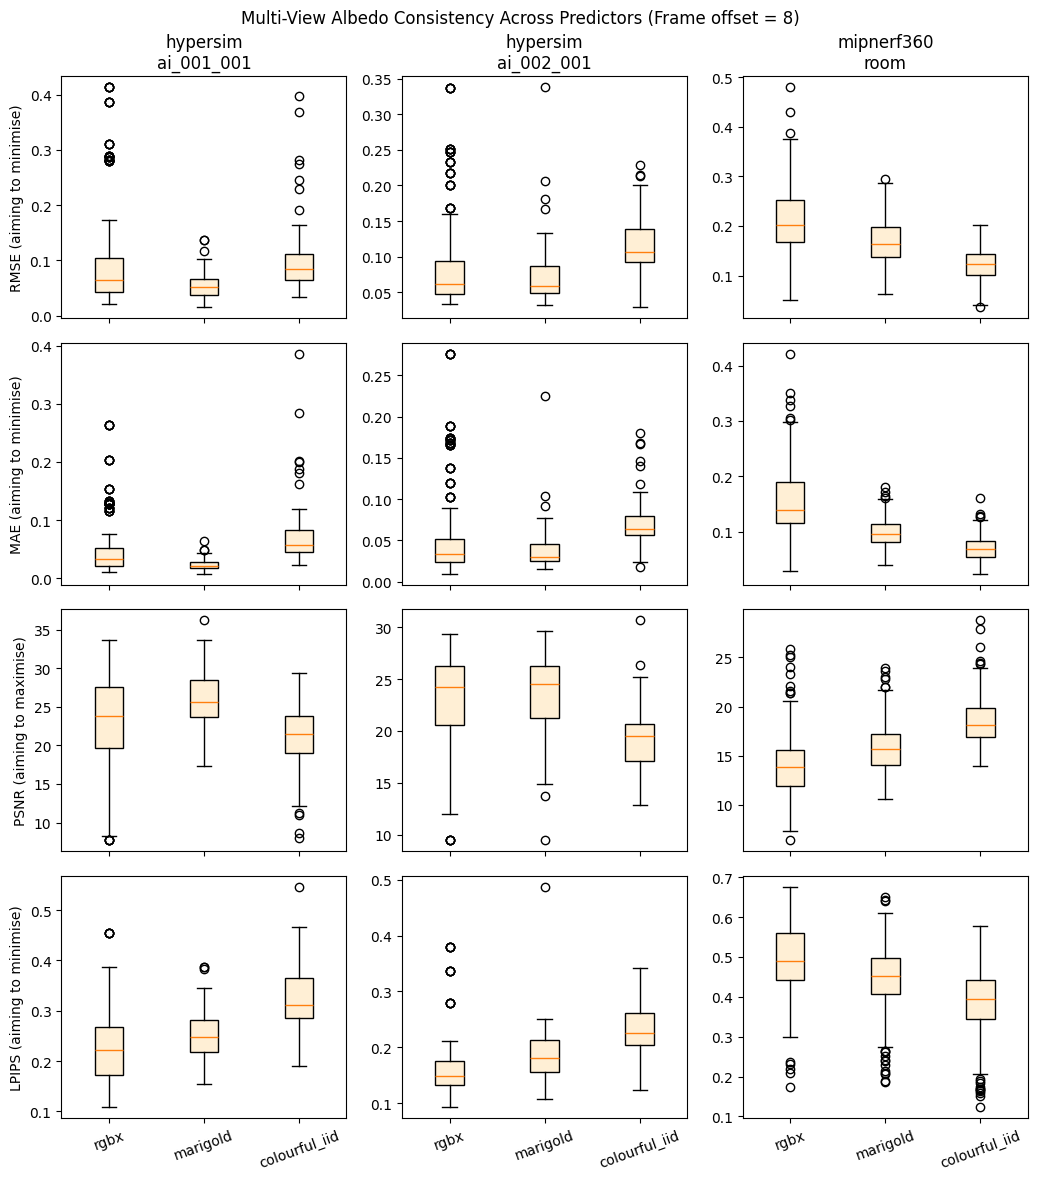

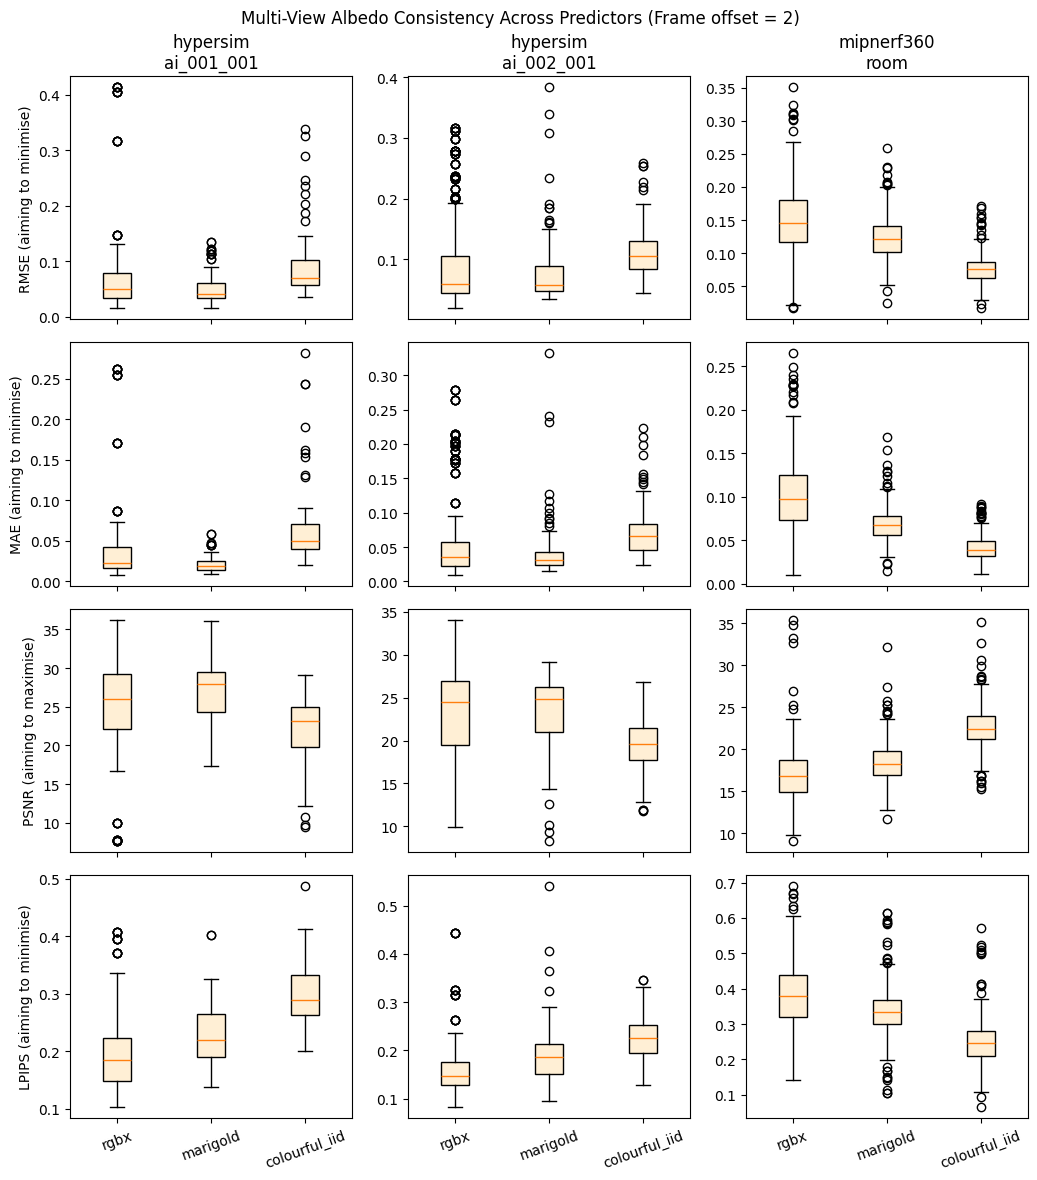

In [28]:
def plot_scene_boxplots(delta: int = 8) -> Figure:
    sub = [r for r in rows if r["delta"] == delta]
    scene_pairs = [(ds, s) for ds, s_list in scenes.items() for s in s_list if any(r["dataset"] == ds and r["scene"] == s for r in sub)]
    if not scene_pairs:
        return

    n_rows, n_cols = len(metrics_key), len(scene_pairs)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.5 * n_cols, 3.0 * n_rows), squeeze=False)
    for i, (metric, metric_label) in enumerate(metrics_key):
        for j, (ds, scene) in enumerate(scene_pairs):
            ax = axes[i, j]
            box_data = [[r[metric] for r in sub if r["dataset"] == ds and r["scene"] == scene and r["predictor"] == pred] for pred in predictors]

            ax.boxplot(box_data, tick_labels=predictors if i == n_rows - 1 else [""] * len(predictors), patch_artist=True, boxprops={"facecolor": "papayawhip"})
            if i == n_rows - 1:
                ax.tick_params(axis="x", rotation=20)
            if i == 0:
                ax.set_title(f"{ds}\n{scene}")
            if j == 0:
                ax.set_ylabel(f"{metric.upper()} ({metric_label})")

    fig.suptitle(f"Multi-View Albedo Consistency Across Predictors (Frame offset = {delta})")
    plt.tight_layout()
    return fig


plot_scene_boxplots(delta=8);
plot_scene_boxplots(delta=2);


saved 3738 rows to /content/drive/.shortcut-targets-by-id/1dLDKtMyEMmBmZHelPG3iGHVN3skbimte/3dgs_decomposition/eval/mv_metrics.csv
saved plot to /content/drive/.shortcut-targets-by-id/1dLDKtMyEMmBmZHelPG3iGHVN3skbimte/3dgs_decomposition/eval/mv_boxplots_delta8.png
saved plot to /content/drive/.shortcut-targets-by-id/1dLDKtMyEMmBmZHelPG3iGHVN3skbimte/3dgs_decomposition/eval/mv_boxplots_delta2.png


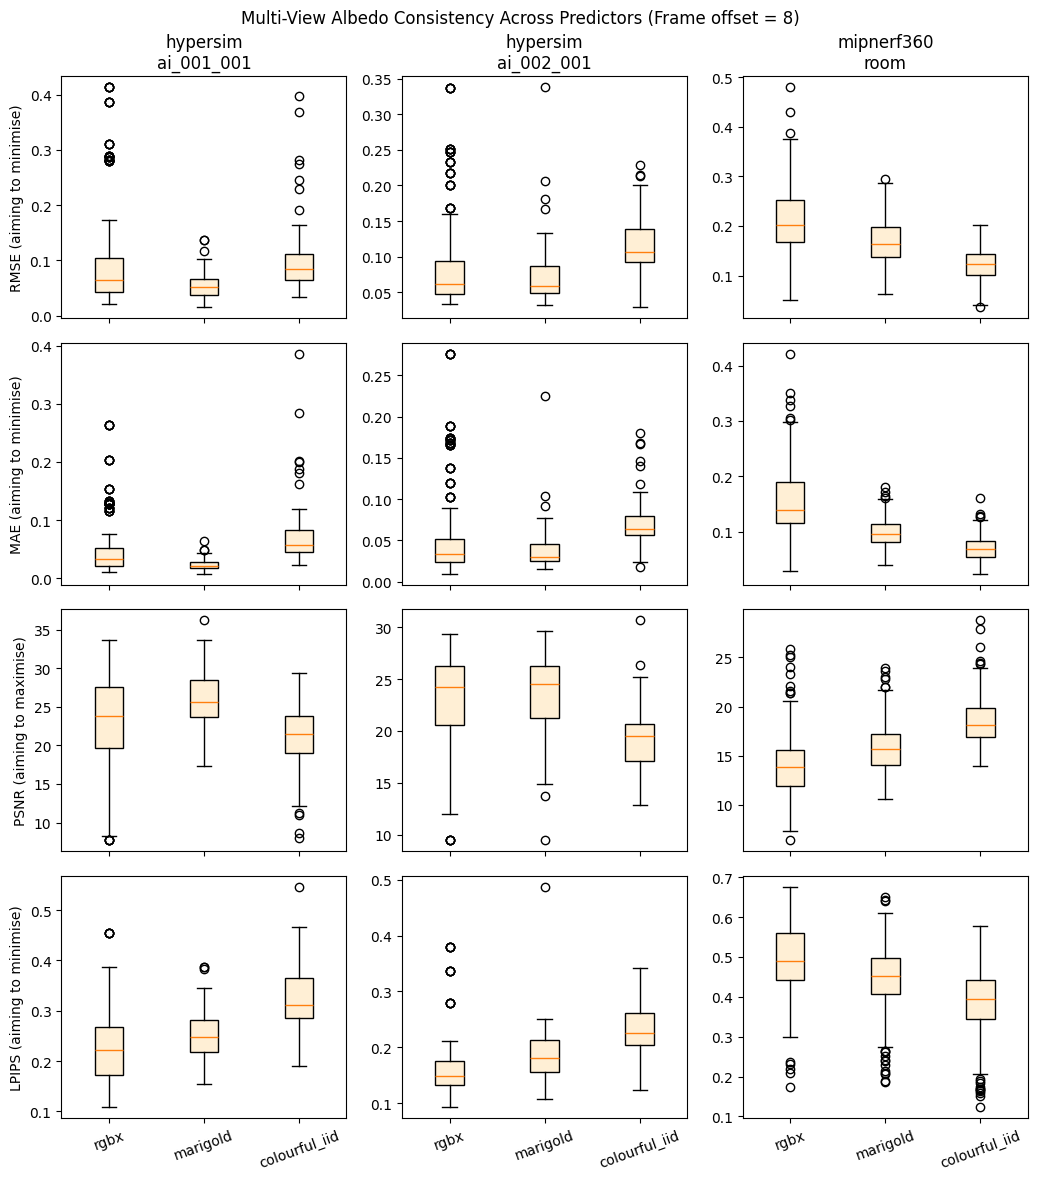

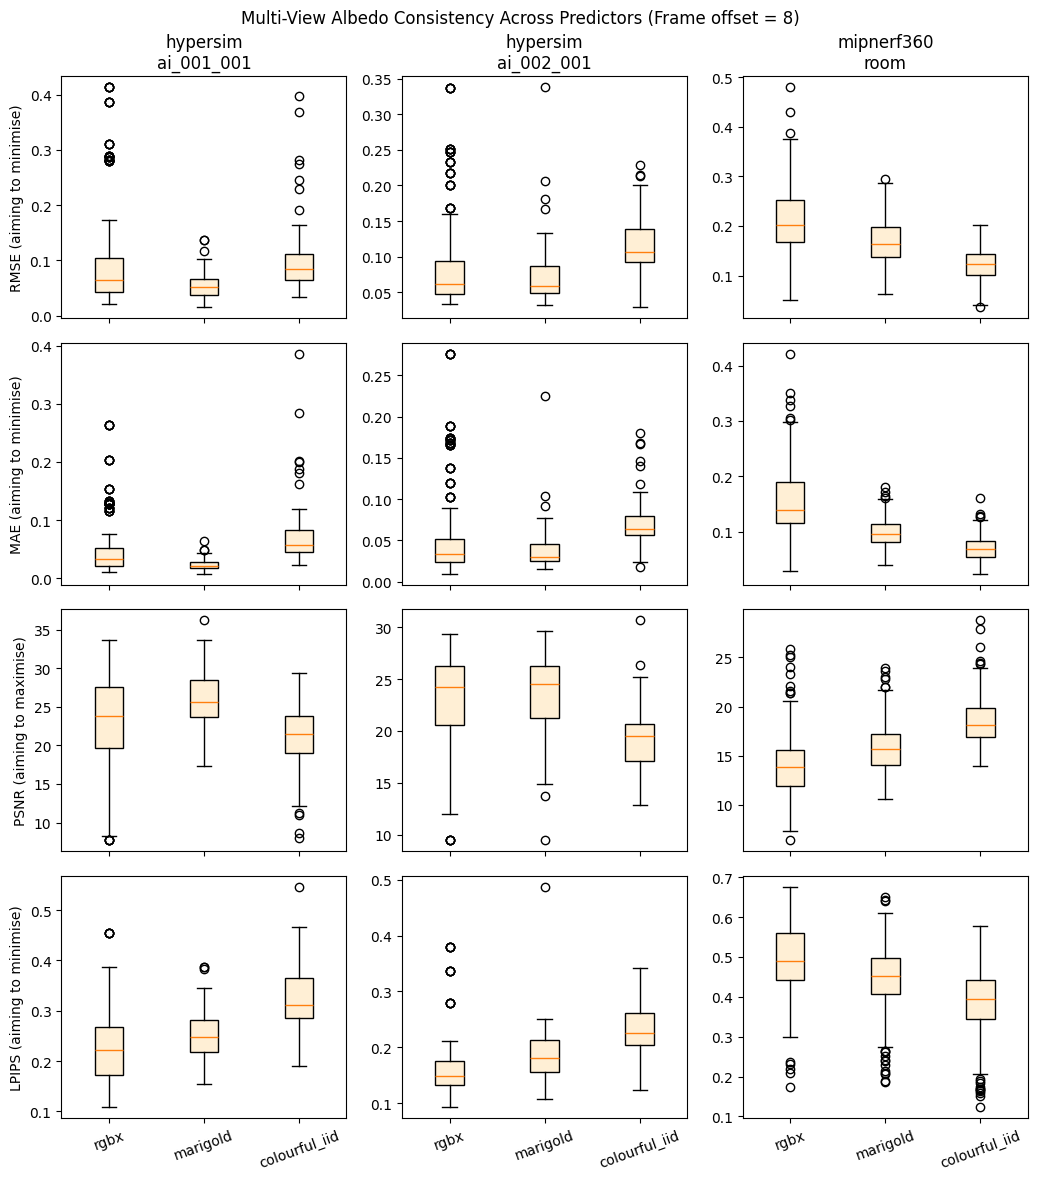

In [29]:
os.makedirs(eval_dir, exist_ok=True)

csv_path = os.path.join(eval_dir, "mv_metrics.csv")
fieldnames = ["predictor", "dataset", "scene", "delta", "src_idx", "tgt_idx", "overlap", "mod_m", "rmse", "mae", "psnr", "lpips"]

with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print(f"saved {len(rows)} rows to {csv_path}")

fig8 = plot_scene_boxplots(delta=8)
plot_path8 = os.path.join(eval_dir, "mv_boxplots_delta8.png")
fig8.savefig(plot_path, dpi=300, bbox_inches="tight")
print(f"saved plot to {plot_path}")

fig2 = plot_scene_boxplots(delta=8)
plot_path2 = os.path.join(eval_dir, "mv_boxplots_delta2.png")
fig2.savefig(plot_path, dpi=300, bbox_inches="tight")
print(f"saved plot to {plot_path}")

In [30]:
df = pd.DataFrame(rows)
raw_cols = ["rmse", "mae", "psnr", "lpips"]
metric_cols = ["rmse (↓)", "mae (↓)", "psnr (↑)", "lpips (↓)"]

df = pd.DataFrame(rows).rename(columns=dict(zip(raw_cols, metric_cols)))

summary = (df.groupby(["delta", "predictor"], sort=False)[metric_cols].mean().reindex(predictors, level="predictor").round(4))

print(summary.to_markdown())

summary_path = os.path.join(root, "eval", "summary_means.csv")
summary.to_csv(summary_path)
print(f"\nsaved summary table to {summary_path}")

|                      |   rmse (↓) |   mae (↓) |   psnr (↑) |   lpips (↓) |
|:---------------------|-----------:|----------:|-----------:|------------:|
| (2, 'rgbx')          |     0.1026 |    0.0647 |    21.939  |      0.2301 |
| (8, 'rgbx')          |     0.1176 |    0.0747 |    20.9009 |      0.2596 |
| (2, 'marigold')      |     0.0977 |    0.0528 |    21.4416 |      0.2816 |
| (8, 'marigold')      |     0.1218 |    0.0675 |    19.8036 |      0.3442 |
| (2, 'colourful_iid') |     0.0884 |    0.0523 |    21.774  |      0.2509 |
| (8, 'colourful_iid') |     0.1173 |    0.071  |    19.1594 |      0.34   |

saved summary table to /content/drive/MyDrive/3dgs_decomposition/eval/summary_means.csv


saved to /content/drive/MyDrive/3dgs_decomposition/eval/warped_compare_hypersim_ai_001_001_d8_pair0.png
saved to /content/drive/MyDrive/3dgs_decomposition/eval/warped_compare_mipnerf360_bicycle_d2_pair0.png


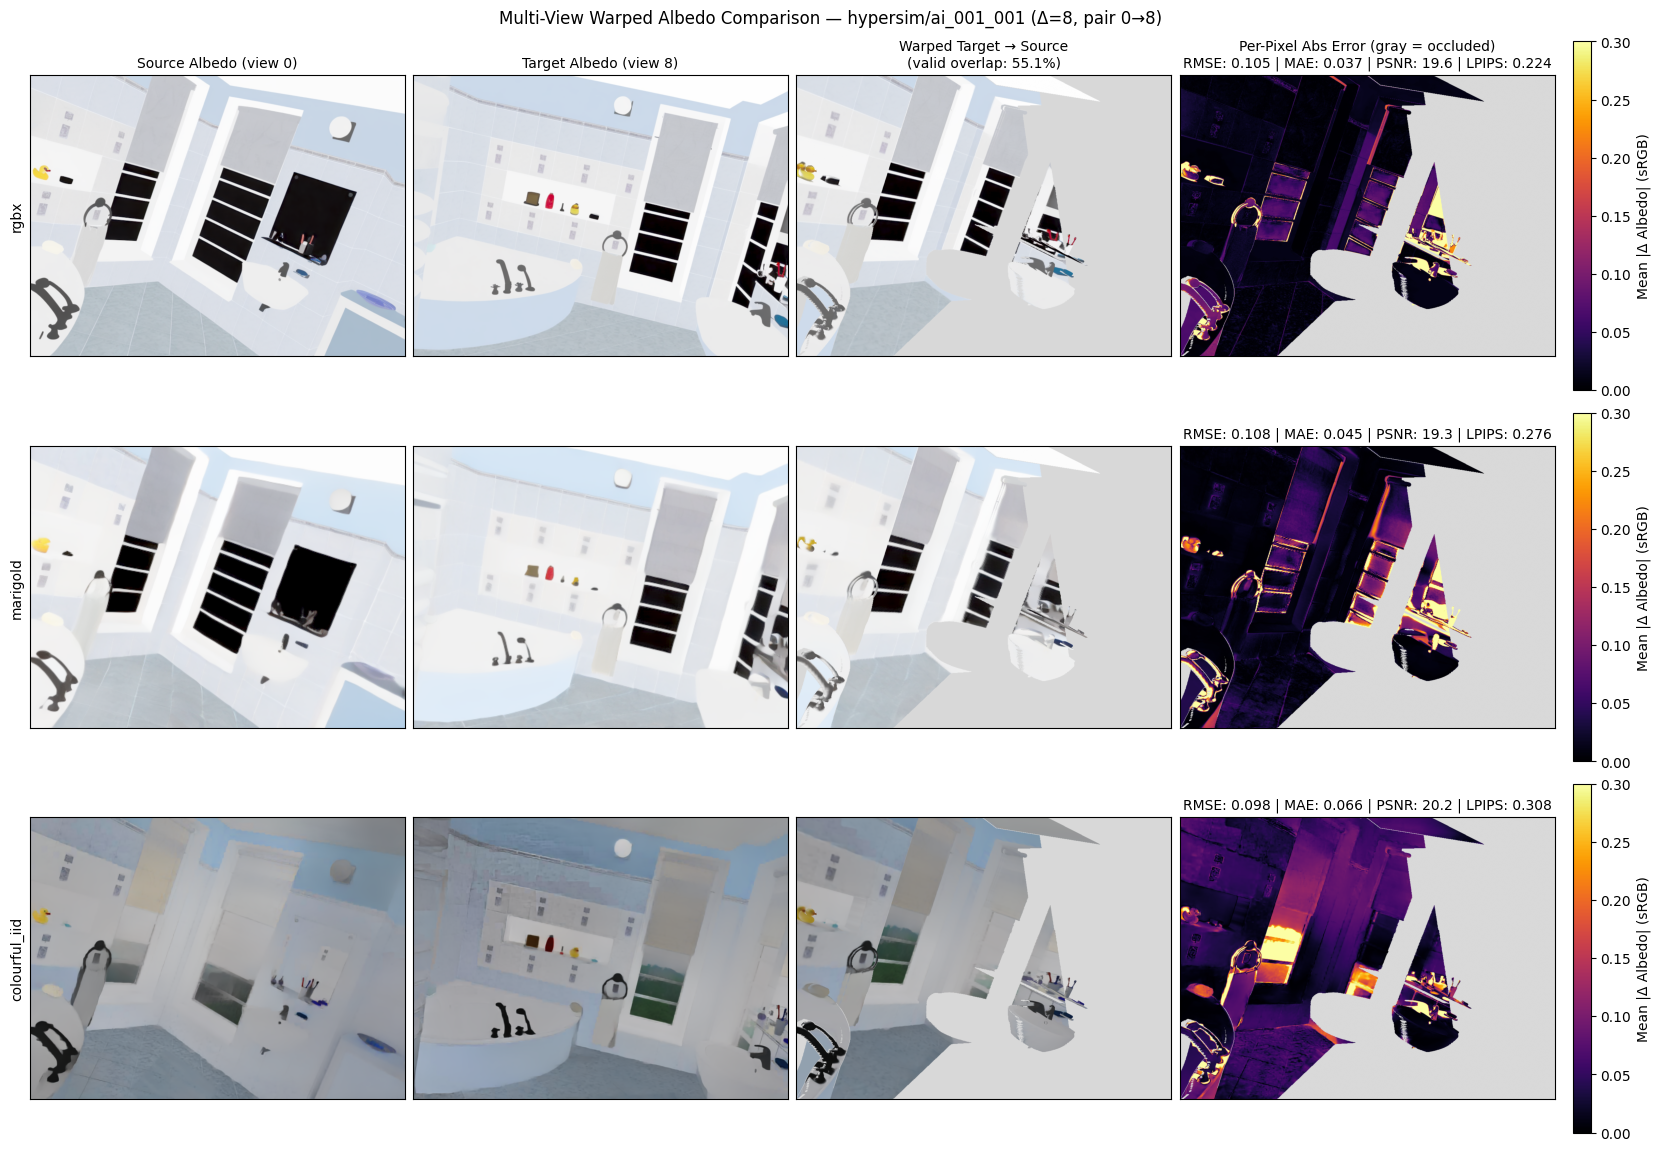

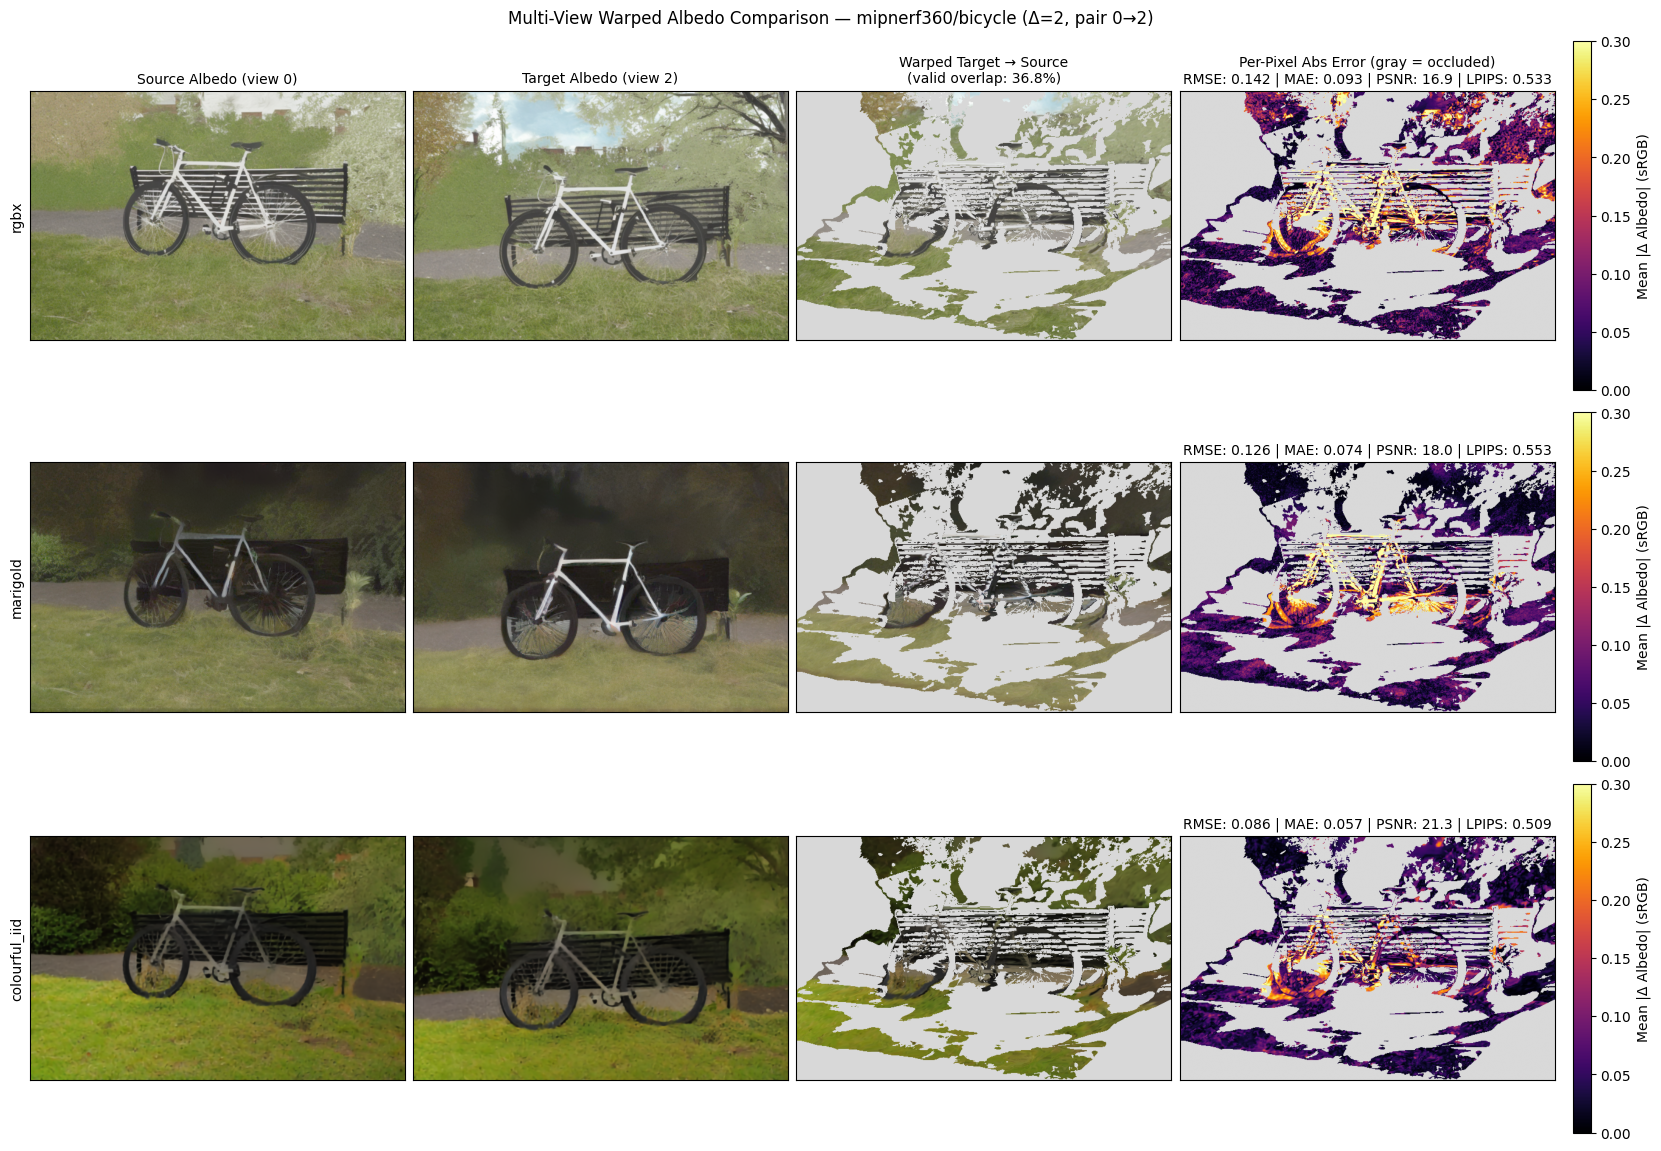

In [37]:
def plot_warped_comparison(dataset: str, scene: str, delta: int = 8, pair_idx: int = 0):
    if (dataset, scene) not in scene_info:
        colmap_dir = (
            os.path.join(root, "data", "hypersim", "colmap_format", scene, "cam_00")
            if dataset == "hypersim"
            else os.path.join(root, "data", "mipnerf360", scene)
        )
        cams = colmap_reader.load_scene_cameras(colmap_dir)
        scene_info[(dataset, scene)] = (cams, reprojection.covisible_pairs(root, dataset, scene, cams))

    cams, pairs_by_diff = scene_info[(dataset, scene)]
    i, j = pairs_by_diff[delta][pair_idx]

    err_cmap = plt.get_cmap("inferno").copy()
    err_cmap.set_bad(color="#d9d9d9")

    fig, axes = plt.subplots(len(predictors), 4, figsize=(16.5, 3.8 * len(predictors)), squeeze=False, constrained_layout=True)

    for row_idx, pred in enumerate(predictors):
        a_i = loaders.load_albedo(loaders.get_albedo_path(root, pred, dataset, scene, cams[i]))
        a_j = loaders.load_albedo(loaders.get_albedo_path(root, pred, dataset, scene, cams[j]))
        d_i = loaders.load_depth(loaders.get_depth_path(root, dataset, scene, cams[i]), a_i.shape[:2])
        d_j = loaders.load_depth(loaders.get_depth_path(root, dataset, scene, cams[j]), a_j.shape[:2])

        warped_j, mask = reprojection.reproject_view(cams[i], cams[j], d_i, d_j, a_j, occ_thresh=thresh, edge_thresh=thresh)

        m = mv_metrics.compute_mv_metrics(a_i, warped_j, mask)

        warped_vis = np.where(mask[..., None], warped_j, 0.85)
        err_map = np.where(mask, np.mean(np.abs(a_i - warped_j), axis=-1), np.nan)

        axes[row_idx, 0].imshow(a_i)
        axes[row_idx, 0].set_ylabel(pred)
        axes[row_idx, 1].imshow(a_j)
        axes[row_idx, 2].imshow(warped_vis)
        im = axes[row_idx, 3].imshow(err_map, cmap=err_cmap, vmin=0.0, vmax=0.3)

        if row_idx == 0:
            axes[row_idx, 0].set_title(f"Source Albedo (view {i})", fontsize=10)
            axes[row_idx, 1].set_title(f"Target Albedo (view {j})", fontsize=10)
            axes[row_idx, 2].set_title(f"Warped Target → Source\n(valid overlap: {m['overlap']:.1%})", fontsize=10)

        header = "Per-Pixel Abs Error (gray = occluded)\n" if row_idx == 0 else ""
        axes[row_idx, 3].set_title(f"{header}RMSE: {m['rmse']:.3f} | MAE: {m['mae']:.3f} | PSNR: {m['psnr']:.1f} | LPIPS: {m['lpips']:.3f}", fontsize=10)

        fig.colorbar(im, ax=axes[row_idx, 3], label="Mean |Δ Albedo| (sRGB)")
        for ax in axes[row_idx]:
            ax.set(xticks=[], yticks=[])

    fig.suptitle(f"Multi-View Warped Albedo Comparison — {dataset}/{scene} (Δ={delta}, pair {i}→{j})")
    out_dir = os.path.join(root, "eval")
    os.makedirs(out_dir, exist_ok=True)
    out_path = os.path.join(out_dir, f"warped_compare_{dataset}_{scene}_d{delta}_pair{pair_idx}.png")
    fig.savefig(out_path, dpi=250, bbox_inches="tight")
    print(f"saved to {out_path}")
    return fig


plot_warped_comparison("hypersim", "ai_001_001", delta=8, pair_idx=0);
plot_warped_comparison("mipnerf360", "bicycle", delta=2, pair_idx=0);
